# Modern (Simple English Wikipedia) – 02 Train & Generation

Fine-tune **SmolLM2-135M** on the Simple English Wikipedia articles cleaned in `01_data.ipynb`, save and reload the checkpoint, and compare generations before and after training.

**Run `01_data.ipynb` first:** it writes `modern_cleaning_output/cleaned_articles.jsonl`, which this notebook reads.

**Deliverables:** training-loss plot, saved checkpoint (reloaded and checked), two before/after examples.

## 1. Setup

In [2]:
import math
from pathlib import Path

import torch
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from datasets import load_dataset, Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForCausalLM, get_cosine_schedule_with_warmup

In [3]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

MODEL_NAME = "HuggingFaceTB/SmolLM2-135M"
DATA_PATH  = "modern_cleaning_output/cleaned_articles.jsonl"   # written by 01_data.ipynb
OUT_DIR    = Path("../../results/modern")
BLOCK      = 256       # tokens per training block
SEED       = 42

EPOCHS, BS, LR = 3, 16, 5e-5

PREFIX_1 = "The Amazon River is"
PREFIX_2 = "In computer science, a"

OUT_DIR.mkdir(parents=True, exist_ok=True)

device: cuda


## 2. Load the cleaned articles

In [4]:
ds = load_dataset("json", data_files=DATA_PATH)["train"]
ds = ds.filter(lambda ex: len(ex["text"].strip()) > 0)
print("articles:", len(ds))

# The data team marked these flags as "needs review"; we leave those articles out.
REVIEW_FLAGS = {"empty_parentheses", "leftover_wiki_markup"}
before_filter = len(ds)
ds = ds.filter(lambda ex: not REVIEW_FLAGS.intersection(ex["flags"]))
print(f"dropped {before_filter - len(ds)} flagged articles -> {len(ds)} left")

print("\n" + ds[0]["title"] + "\n" + ds[0]["text"][:500])

Generating train split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/500 [00:00<?, ? examples/s]

articles: 500


Filter:   0%|          | 0/500 [00:00<?, ? examples/s]

dropped 26 flagged articles -> 474 left

April
April (Apr.) is the fourth month of the year in the Julian and Gregorian calendars, and comes between March and May. It is one of the four months to have 30 days.

April always begins on the same day of the week as July, and additionally, January in leap years. April always ends on the same day of the week as December.

April comes between March and May, making it the fourth month of the year. It also comes first in the year out of the four months that have 30 days, as June, September and Novemb


In [5]:
# Contiguous 90/10 split by article (no shuffle), so test articles are never seen in training.
data = ds.train_test_split(test_size=0.1, shuffle=False)
data

DatasetDict({
    train: Dataset({
        features: ['title', 'text', 'flags'],
        num_rows: 426
    })
    test: Dataset({
        features: ['title', 'text', 'flags'],
        num_rows: 48
    })
})

**Formatting notes**
- Text was cleaned by the data team (`modern_english_cleaning.py`): wiki markup, citations and back-matter sections removed.
- Articles already use `\n\n` between their own paragraphs, so we mark the end of each article with the `<|endoftext|>` (EOS) token instead.

## 3. Tokenizer and model

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).float().to(device)

print("params:", model.num_parameters())
print("eos:", tokenizer.eos_token, tokenizer.eos_token_id, "| pad:", tokenizer.pad_token, "| vocab:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/704 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.66k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/801k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  269MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

params: 134515008
eos: <|endoftext|> 0 | pad: None | vocab: 49152


In [14]:
data['train']['flags'][-1]

[]

In [15]:
# Quick look at how text becomes tokens.
example = data["train"][0]["text"][:200]
ids = tokenizer(example)["input_ids"]
print(list(zip(ids, tokenizer.convert_ids_to_tokens(ids)))[:20])
print("round trip ok:", tokenizer.decode(ids) == example)
print(f"chars per token: {len(example) / len(ids):.2f}")

[(16732, 'April'), (365, 'Ġ('), (41966, 'Apr'), (2677, '.)'), (314, 'Ġis'), (260, 'Ġthe'), (8629, 'Ġfourth'), (3531, 'Ġmonth'), (282, 'Ġof'), (260, 'Ġthe'), (713, 'Ġyear'), (281, 'Ġin'), (260, 'Ġthe'), (27185, 'ĠJulian'), (284, 'Ġand'), (42612, 'ĠGregorian'), (36229, 'Ġcalendars'), (28, ','), (284, 'Ġand'), (2216, 'Ġcomes')]
round trip ok: True
chars per token: 4.08


## 4. Before training: generation

In [16]:
gen_kwargs = dict(
    max_new_tokens=120,
    do_sample=True,
    temperature=0.8,
    top_p=0.9,
    pad_token_id=tokenizer.eos_token_id,
)

def generate_text(m, prefix, seed=SEED):
    m.eval()
    with torch.inference_mode():
        enc = tokenizer(prefix, return_tensors="pt").to(device)
        torch.manual_seed(seed)
        out = m.generate(**enc, **gen_kwargs)
    return tokenizer.decode(out[0])

before_1 = generate_text(model, PREFIX_1)
before_2 = generate_text(model, PREFIX_2)
print(before_1, "\n" + "=" * 60 + "\n" + before_2)

The Amazon River is a major source of water for much of the world. This article is about the Amazon River, its tributaries, and the Amazon Rainforest.

The Amazon River is the second largest river in South America, after the Amazon. The Amazon River, which flows from southern Brazil, flows through a wide area in the South American country of Brazil. The river is one of the longest rivers in the world, and its source is in the Andes Mountains.

The Amazon River is important to the life of many people in the Amazon Rainforest. For example, the Amazon River provides water to many cities in Brazil 
In computer science, a "temporary data structure" is a type of container used for storing data until the user deletes it. In the context of web development, temporary data structures are used to store data in memory that will be deleted once the web application is finished. For example, when a user logs into a website, he/she would typically use a temporary data structure to store his/her userna

## 5. Build 256-token blocks

In [17]:
def stream_ids(texts):
    # tokenize each article and add EOS after it, so the model sees where articles end
    ids = []
    for t in texts:
        ids += tokenizer(t)["input_ids"] + [tokenizer.eos_token_id]
    return ids

def make_blocks(ids, block=BLOCK):
    n = len(ids) // block                      # leftover tail is dropped
    return [ids[i * block:(i + 1) * block] for i in range(n)]

def to_ds(blocks):
    # labels = copy of input_ids; the model shifts them internally
    return Dataset.from_dict({"input_ids": blocks, "labels": [b.copy() for b in blocks]})

train_ids = stream_ids(data["train"]["text"])
test_ids  = stream_ids(data["test"]["text"])

train_blocks, test_blocks = make_blocks(train_ids), make_blocks(test_ids)
assert all(len(b) == BLOCK for b in train_blocks + test_blocks)

lm_data = DatasetDict({
    "train": to_ds(train_blocks).shuffle(seed=SEED),   # shuffle train only
    "test":  to_ds(test_blocks),
})
print(f"train: {len(train_ids):,} tokens -> {len(train_blocks)} blocks")
print(f"test:  {len(test_ids):,} tokens -> {len(test_blocks)} blocks")

train: 388,807 tokens -> 1518 blocks
test:  36,505 tokens -> 142 blocks


In [18]:
print(tokenizer.decode(lm_data["train"][0]["input_ids"])[:600])

7, the state became a republic. Northern Ireland stayed with the UK, and this would lead to The Troubles beginning in the 1960s and ending with the Good Friday Agreement signed in 1998.

Facts
The flag colours of the Republic of Ireland are green, white and orange.
A symbol of Ireland is the shamrock.
Popular games in Ireland include Gaelic football and hurling.
The population of the Republic of Ireland is around 4.7 million.
The president of the Republic of Ireland is Michael D. Higgins.
The two parts of Ireland are the Republic of Ireland and Northern Ireland.
The River Shannon, which runs f


## 6. Fine-tune

In [19]:
torch.manual_seed(SEED)

lm_data.set_format("torch", columns=["input_ids", "labels"])
train_loader = DataLoader(lm_data["train"], batch_size=BS, shuffle=True)
test_loader  = DataLoader(lm_data["test"],  batch_size=BS)

opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
total_steps = EPOCHS * len(train_loader)
sched = get_cosine_schedule_with_warmup(opt, int(0.03 * total_steps), total_steps)

@torch.no_grad()
def evaluate():
    model.eval()
    tot, n = 0.0, 0
    for b in test_loader:
        ids, lab = b["input_ids"].to(device), b["labels"].to(device)
        tot += model(input_ids=ids, labels=lab).loss.item() * ids.size(0)
        n += ids.size(0)
    model.train()
    return tot / n

In [20]:
v = evaluate()
print(f"before training | val loss {v:.4f} | ppl {math.exp(v):.2f}")

log_steps, log_losses, val_losses = [], [], []
step = 0
model.train()
for epoch in range(1, EPOCHS + 1):
    for b in train_loader:
        ids, lab = b["input_ids"].to(device), b["labels"].to(device)
        loss = model(input_ids=ids, labels=lab).loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step(); sched.step(); opt.zero_grad(set_to_none=True)

        step += 1
        if step == 1 or step % 10 == 0:
            log_steps.append(step); log_losses.append(loss.item())
            print(f"step {step}/{total_steps} | loss {loss.item():.4f}")

    v = evaluate()
    val_losses.append(v)
    print(f"epoch {epoch} | val loss {v:.4f} | ppl {math.exp(v):.2f}")
    ckpt_dir = OUT_DIR / f"ckpt_epoch{epoch}"
    model.save_pretrained(ckpt_dir)
    tokenizer.save_pretrained(ckpt_dir)

before training | val loss 2.4394 | ppl 11.47
step 1/285 | loss 2.4330
step 10/285 | loss 2.4484
step 20/285 | loss 2.3607
step 30/285 | loss 2.2829
step 40/285 | loss 2.4604
step 50/285 | loss 2.3023
step 60/285 | loss 2.5604
step 70/285 | loss 2.4606
step 80/285 | loss 2.4418
step 90/285 | loss 2.4333
epoch 1 | val loss 2.3682 | ppl 10.68


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

step 100/285 | loss 2.2258
step 110/285 | loss 2.0855
step 120/285 | loss 2.1562
step 130/285 | loss 2.1658
step 140/285 | loss 2.1180
step 150/285 | loss 2.1971
step 160/285 | loss 1.9659
step 170/285 | loss 2.0667
step 180/285 | loss 1.9881
step 190/285 | loss 1.9849
epoch 2 | val loss 2.3758 | ppl 10.76


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

step 200/285 | loss 2.1562
step 210/285 | loss 2.1081
step 220/285 | loss 2.0077
step 230/285 | loss 2.1234
step 240/285 | loss 2.0157
step 250/285 | loss 1.9087
step 260/285 | loss 1.8767
step 270/285 | loss 2.1156
step 280/285 | loss 2.0999
epoch 3 | val loss 2.3844 | ppl 10.85


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

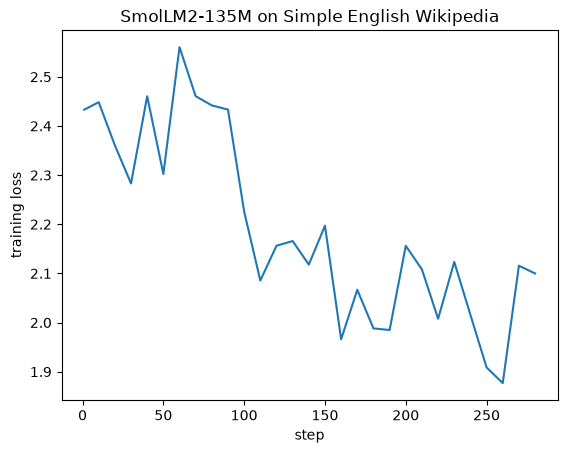

In [21]:
plt.plot(log_steps, log_losses)
plt.xlabel("step"); plt.ylabel("training loss"); plt.title("SmolLM2-135M on Simple English Wikipedia")
plt.savefig(OUT_DIR / "train_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Save and reload check

Load the last checkpoint from disk as a brand-new model and generate with the same prefix and seed as the model still in memory. If saving worked, the two outputs are identical.

In [22]:
reloaded = AutoModelForCausalLM.from_pretrained(OUT_DIR / f"ckpt_epoch{EPOCHS}").to(device)

from_memory = generate_text(model, PREFIX_1)
from_disk   = generate_text(reloaded, PREFIX_1)
print("reload matches in-memory model:", from_memory == from_disk)
del reloaded

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

reload matches in-memory model: True


## 8. Load the best checkpoint

In [23]:
best_epoch = min(range(len(val_losses)), key=lambda i: val_losses[i]) + 1
ckpt = OUT_DIR / f"ckpt_epoch{best_epoch}"
print("best:", ckpt, "| val loss", round(val_losses[best_epoch - 1], 4))

tuned = AutoModelForCausalLM.from_pretrained(ckpt).to(device)

best: ../../results/modern/ckpt_epoch1 | val loss 2.3682


Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

## 9. After training: generation

In [24]:
after_1 = generate_text(tuned, PREFIX_1)
after_2 = generate_text(tuned, PREFIX_2)

for name, b, a in [("prefix 1", before_1, after_1), ("prefix 2", before_2, after_2)]:
    print(f"##### {name} — BEFORE #####\n{b}\n")
    print(f"##### {name} — AFTER #####\n{a}\n")

##### prefix 1 — BEFORE #####
The Amazon River is a major source of water for much of the world. This article is about the Amazon River, its tributaries, and the Amazon Rainforest.

The Amazon River is the second largest river in South America, after the Amazon. The Amazon River, which flows from southern Brazil, flows through a wide area in the South American country of Brazil. The river is one of the longest rivers in the world, and its source is in the Andes Mountains.

The Amazon River is important to the life of many people in the Amazon Rainforest. For example, the Amazon River provides water to many cities in Brazil

##### prefix 1 — AFTER #####
The Amazon River is the largest river in South America, and the second largest river in the world. It is the fourth largest river on Earth. The river is the fourth largest river by the volume of water in the world, after the Nile, the Ganges, and the Amazon River.

The Amazon River is the largest river in the world, and one of the world'

## 10. Observations

- **Data:** 500 Simple English Wikipedia articles cleaned by the data team; 26 flagged articles (empty parentheses, leftover wiki markup) dropped, leaving 474. Articles are separated by the EOS token, since articles already use `\n\n` between paragraphs.
- **Settings:** seed 42, `max_new_tokens=120`, temperature 0.8, top-p 0.9; identical before and after. 3 epochs, batch 16, LR 5e-5 (cosine, 3% warmup), A40.
- **Loss:** val loss 2.44 (ppl 11.5) before training → **2.37** / 2.38 / 2.38 after epochs 1–3. Best checkpoint: epoch 1. Val loss rises in epochs 2–3 while train loss keeps falling, so the model starts memorizing after one epoch; one epoch would have been enough. The gain is smaller than for Shakespeare because the base model already knows Wikipedia-style English.
- **Reload check:** the reloaded checkpoint produces the same output as the in-memory model: True.
- **Prefix 1 (Amazon):** already encyclopedic before training; after, slightly shorter and plainer sentences. Facts are unreliable in both (contradictory river rankings).
- **Prefix 2 (computer science):** before reads like a web tutorial; after is Simple English Wikipedia style: a short definition, very simple sentences, a plain one-item-per-line list, and it ends with `<|endoftext|>`, showing the model learned where articles end.
- **Partners:** my partner left the team, so I completed this task alone and can explain every step.
- **Limitations:** one sample per prefix (single seed).